In [ ]:
#this is a simple prediction model meant to predict the price without including the time aspect
#goal is to find prices based on all other variables


#test test
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split 
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

In [2]:
data = pd.read_parquet("C:/Users/tommy/OneDrive/Documents/GitHub/data-science-capstone/Data/cleaned_data/merged.parguet", engine="fastparquet")
data = data.dropna()
data

,interval_start_utc,interval_end_utc,publish_time_utc,north_derated_outages_mw,north_forced_outages_mw,north_planned_outages_mw,north_unplanned_outages_mw,central_derated_outages_mw,central_forced_outages_mw,central_planned_outages_mw,...,south_wind,miso_wind,north_solar,central_solar,south_solar,miso_solar,lmp_dam,energy_dam,congestion_dam,loss_dam
0,2023-03-25 01:55:00+00:00,2023-03-25 02:00:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,9920.8,3.9,1.0,1.2,6.1,26.92,26.09,1.66,-0.83
1,2023-03-25 02:00:00+00:00,2023-03-25 02:05:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
2,2023-03-25 02:05:00+00:00,2023-03-25 02:10:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
3,2023-03-25 02:10:00+00:00,2023-03-25 02:15:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
4,2023-03-25 02:15:00+00:00,2023-03-25 02:20:00+00:00,2023-03-23 05:00:00+00:00,399.0,155.0,2895.0,285.0,1999.0,3006.0,18439.0,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
366307,2026-09-16 23:30:00+00:00,2026-09-16 23:35:00+00:00,2026-09-15 05:00:00+00:00,1641.0,1812.0,3536.0,99.0,6771.0,4415.0,10190.0,...,48.8,3865.8,98.9,684.2,645.1,1428.2,159.93,390.14,-220.71,-9.50
366308,2026-09-16 23:35:00+00:00,2026-09-16 23:40:00+00:00,2026-09-15 05:00:00+00:00,1641.0,1812.0,3536.0,99.0,6771.0,4415.0,10190.0,...,48.8,3865.8,98.9,684.2,645.1,1428.2,159.93,390.14,-220.71,-9.50
366309,2026-09-16 23:40:00+00:00,2026-09-16 23:45:00+00:00,2026-09-15 05:00:00+00:00,1641.0,1812.0,3536.0,99.0,6771.0,4415.0,10190.0,...,48.8,3865.8,98.9,684.2,645.1,1428.2,159.93,390.14,-220.71,-9.50
366310,2026-09-16 23:45:00+00:00,2026-09-16 23:50:00+00:00,2026-09-15 05:00:00+00:00,1641.0,1812.0,3536.0,99.0,6771.0,4415.0,10190.0,...,48.8,3865.8,98.9,684.2,645.1,1428.2,159.93,390.14,-220.71,-9.50


**Random Forest Regressor**

In [37]:
#cap price at 1000
data["lmp_rtm"] = data["lmp_rtm"].clip(upper=1000)

#convert timestamp to datetime
data["interval_end_utc"] = pd.to_datetime(data["interval_end_utc"], utc=True, errors="coerce")

#set cutoff for data split and validation
test_start = pd.Timestamp("2026-01-01", tz="UTC")
validation_start = pd.Timestamp("2025-07-01", tz="UTC")

#create the training, testing, and validation data
train_data = data.loc[data["interval_end_utc"] < validation_start].copy()
test_data = data.loc[data["interval_end_utc"] >= test_start].copy()
validation_data = data.loc[
    (data["interval_end_utc"] >= validation_start) &
    (data["interval_end_utc"] < test_start)
].copy()

#show number of rows each category holds
print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))
print("Testing rows:", len(test_data))

#Split features
features = ["energy_dam", "congestion_dam", "loss_dam", "miso_wind", "miso_solar", "miso_derated_outages_mw", "miso_forced_outages_mw", "miso_planned_outages_mw", "miso_unplanned_outages_mw"]

X_train = train_data[features]
y_train = train_data["lmp_rtm"]

X_val = validation_data[features]
y_val = validation_data["lmp_rtm"]

#random forest regression
model = RandomForestRegressor(n_estimators=200, random_state=1)
model.fit(X_train, y_train)
val_prediction = model.predict(X_val)

#evaluate
rf_mae = mean_absolute_error(y_val, val_prediction)
rf_rmse = math.sqrt(mean_squared_error(y_val, val_prediction))
rf_r2 = r2_score(y_val, val_prediction)
print("RMSE: ", rf_rmse)
print("MAE: ", rf_mae)
print("R2: ", rf_r2)

Training rows: 230966
Validation rows: 51831
Testing rows: 71923
RMSE:  53.176384689489986
MAE:  23.82835629256539
R2:  0.004754441211510363


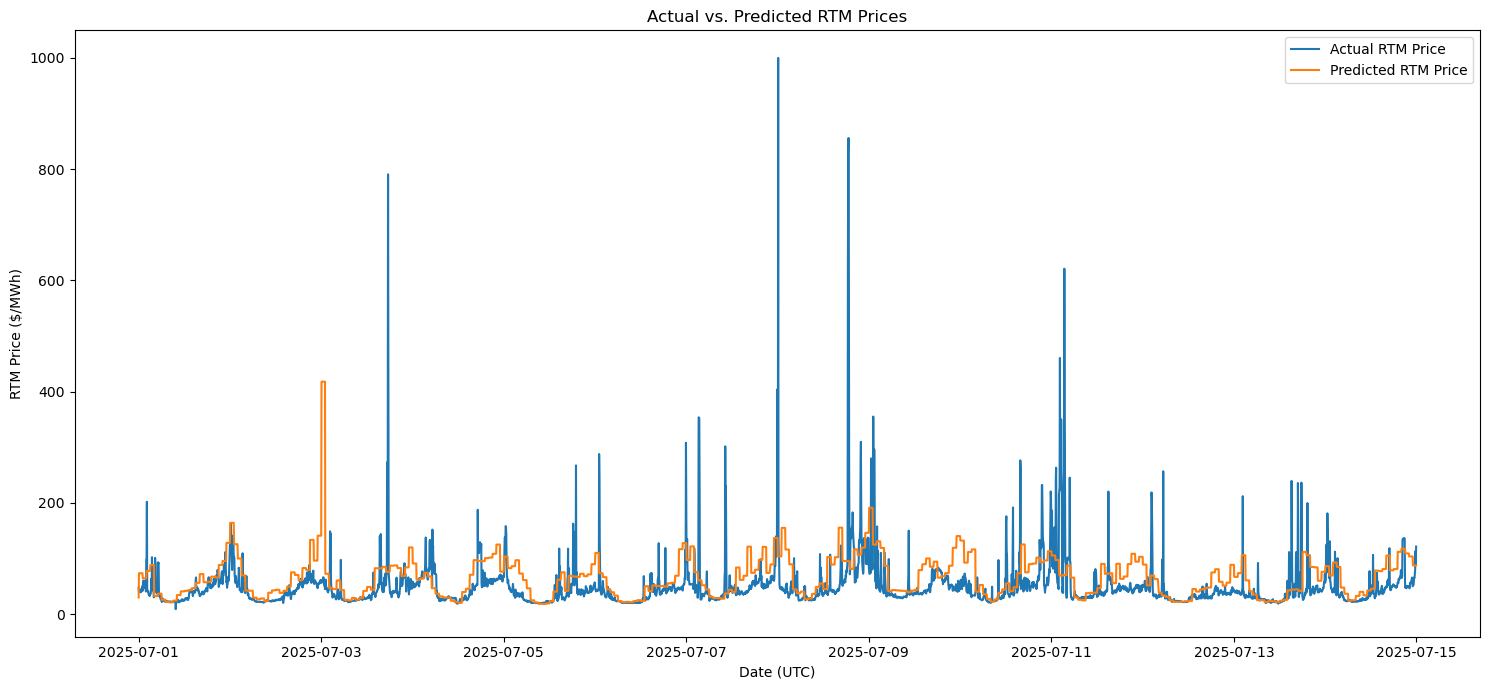

In [ ]:
#Plotting the data
validation_results = validation_data[["interval_end_utc", "lmp_rtm"]].copy()
validation_results["predicted"] = val_prediction
plt.figure(figsize=(15, 7))

#show results for only 1 month
month_start = pd.Timestamp("2025-07-01", tz="UTC")
month_end = pd.Timestamp("2025-07-15", tz="UTC")
monthly_results = validation_results.loc[
    (validation_results["interval_end_utc"] >= month_start) &
    (validation_results["interval_end_utc"] < month_end)
]


plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["lmp_rtm"],
    label = "Actual RTM Price"
)

plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["predicted"],
    label = "Predicted RTM Price"
)


plt.xlabel("Date (UTC)")
plt.ylabel("RTM Price ($/MWh)")
plt.title("Actual vs. Predicted RTM Prices (Random Forest Regressor)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#creating the price forecast vectors (will be worked on at a later date)

FORECAST_HORIZON = 288
STRIDE_STEPS = 300

#combine timestamps and predictions
validation_results = validation_data[["interval_end_utc", "lmp_rtm"]].copy()
validation_results["predicted"] = val_prediction
validation_results


,interval_end_utc,lmp_rtm,predicted
238728,2025-07-01 00:00:00+00:00,47.73,29.990967
238729,2025-07-01 00:05:00+00:00,39.41,73.642528
238730,2025-07-01 00:10:00+00:00,42.63,73.642528
238731,2025-07-01 00:15:00+00:00,42.11,73.642528
238732,2025-07-01 00:20:00+00:00,39.67,73.642528
...,...,...,...
291715,2025-12-31 23:35:00+00:00,34.11,50.754204
291716,2025-12-31 23:40:00+00:00,45.13,50.754204
291717,2025-12-31 23:45:00+00:00,31.83,50.754204
291718,2025-12-31 23:50:00+00:00,31.86,50.754204


**XGBRegressor**

In [38]:
#cap price at 1000
data["lmp_rtm"] = data["lmp_rtm"].clip(upper=1000)

#convert timestamp to datetime
data["interval_end_utc"] = pd.to_datetime(data["interval_end_utc"], utc=True, errors="coerce")

#set cutoff for data split and validation
test_start = pd.Timestamp("2026-01-01", tz="UTC")
validation_start = pd.Timestamp("2025-07-01", tz="UTC")

#create the training, testing, and validation data
train_data = data.loc[data["interval_end_utc"] < validation_start].copy()
test_data = data.loc[data["interval_end_utc"] >= test_start].copy()
validation_data = data.loc[
    (data["interval_end_utc"] >= validation_start) &
    (data["interval_end_utc"] < test_start)
].copy()

#show number of rows each category holds
print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))
print("Testing rows:", len(test_data))

#Split features
features = ["energy_dam", "congestion_dam", "loss_dam", "miso_wind", "miso_solar", "miso_derated_outages_mw", "miso_forced_outages_mw", "miso_planned_outages_mw", "miso_unplanned_outages_mw"]

X_train = train_data[features]
y_train = train_data["lmp_rtm"]

X_val = validation_data[features]
y_val = validation_data["lmp_rtm"]

#XGB Regressor
model = XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=5, subsample=0.8, random_state=1)
model.fit(X_train, y_train)
val_prediction = model.predict(X_val)

#evaluate
xgb_mae = mean_absolute_error(y_val, val_prediction)
xgb_rmse = math.sqrt(mean_squared_error(y_val, val_prediction))
xgb_r2 = r2_score(y_val, val_prediction)
print("RMSE: ", xgb_rmse)
print("MAE: ", xgb_mae)
print("R2: ", xgb_r2)

Training rows: 230966
Validation rows: 51831
Testing rows: 71923
RMSE:  52.52333419587034
MAE:  22.18176359360994
R2:  0.029049235576348753


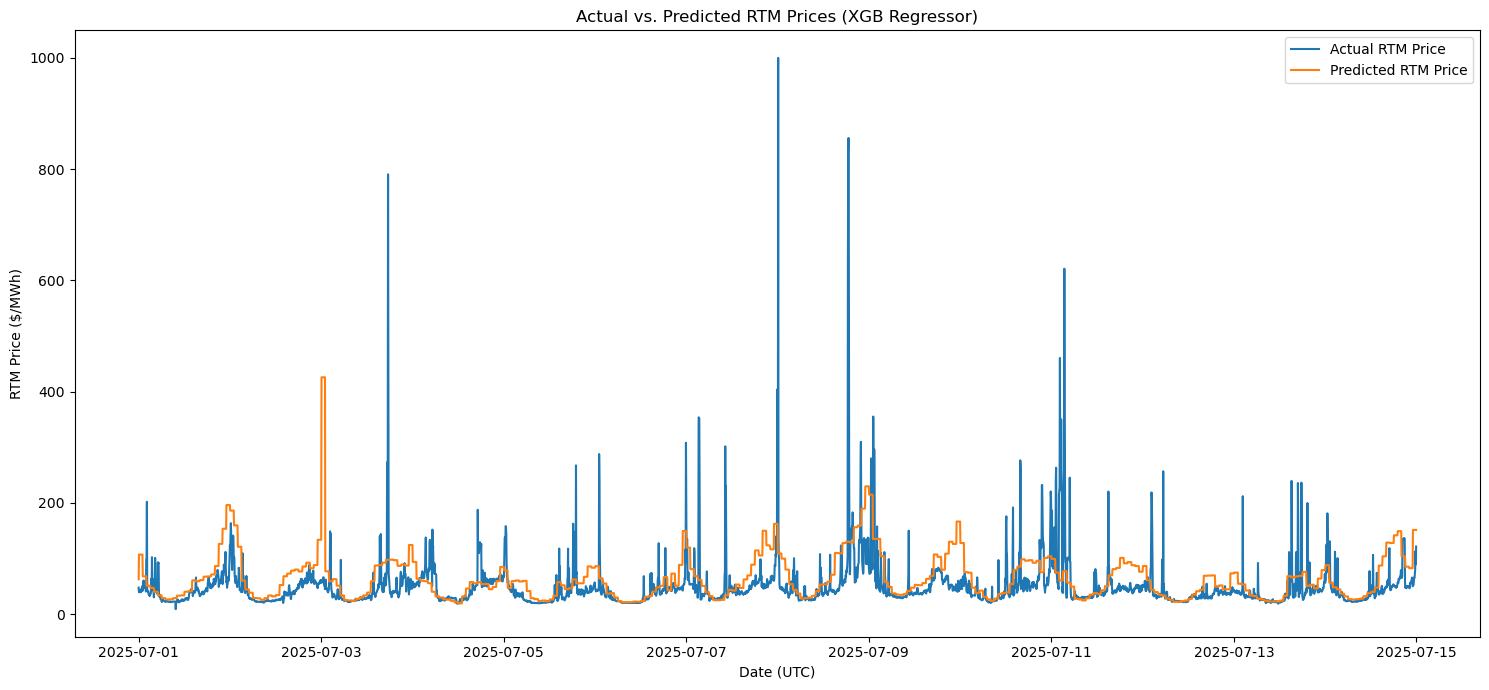

In [27]:
#Plotting the data
validation_results = validation_data[["interval_end_utc", "lmp_rtm"]].copy()
validation_results["predicted"] = val_prediction
plt.figure(figsize=(15, 7))

#show results for only 1 month
month_start = pd.Timestamp("2025-07-01", tz="UTC")
month_end = pd.Timestamp("2025-07-15", tz="UTC")
monthly_results = validation_results.loc[
    (validation_results["interval_end_utc"] >= month_start) &
    (validation_results["interval_end_utc"] < month_end)
]


plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["lmp_rtm"],
    label = "Actual RTM Price"
)

plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["predicted"],
    label = "Predicted RTM Price"
)


plt.xlabel("Date (UTC)")
plt.ylabel("RTM Price ($/MWh)")
plt.title("Actual vs. Predicted RTM Prices (XGB Regressor)")
plt.legend()
plt.tight_layout()
plt.show()

**Hist Gradient Boosting Regressor**

In [39]:
#cap price at 1000
data["lmp_rtm"] = data["lmp_rtm"].clip(upper=1000)

#convert timestamp to datetime
data["interval_end_utc"] = pd.to_datetime(data["interval_end_utc"], utc=True, errors="coerce")

#set cutoff for data split and validation
test_start = pd.Timestamp("2026-01-01", tz="UTC")
validation_start = pd.Timestamp("2025-07-01", tz="UTC")

#create the training, testing, and validation data
train_data = data.loc[data["interval_end_utc"] < validation_start].copy()
test_data = data.loc[data["interval_end_utc"] >= test_start].copy()
validation_data = data.loc[
    (data["interval_end_utc"] >= validation_start) &
    (data["interval_end_utc"] < test_start)
].copy()

#show number of rows each category holds
print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))
print("Testing rows:", len(test_data))

#Split features
features = ["energy_dam", "congestion_dam", "loss_dam", "miso_wind", "miso_solar", "miso_derated_outages_mw", "miso_forced_outages_mw", "miso_planned_outages_mw", "miso_unplanned_outages_mw"]

X_train = train_data[features]
y_train = train_data["lmp_rtm"]

X_val = validation_data[features]
y_val = validation_data["lmp_rtm"]

#Hist Gradient Boosting Regressor
model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=63, random_state=1)
model.fit(X_train, y_train)
val_prediction = model.predict(X_val)

#evaluate
hist_mae = mean_absolute_error(y_val, val_prediction)
hist_rmse = math.sqrt(mean_squared_error(y_val, val_prediction))
hist_r2 = r2_score(y_val, val_prediction)
print("RMSE: ", hist_rmse)
print("MAE: ", hist_mae)
print("R2: ", hist_r2)

Training rows: 230966
Validation rows: 51831
Testing rows: 71923
RMSE:  53.70575247361592
MAE:  22.75388480018115
R2:  -0.015159410557855857


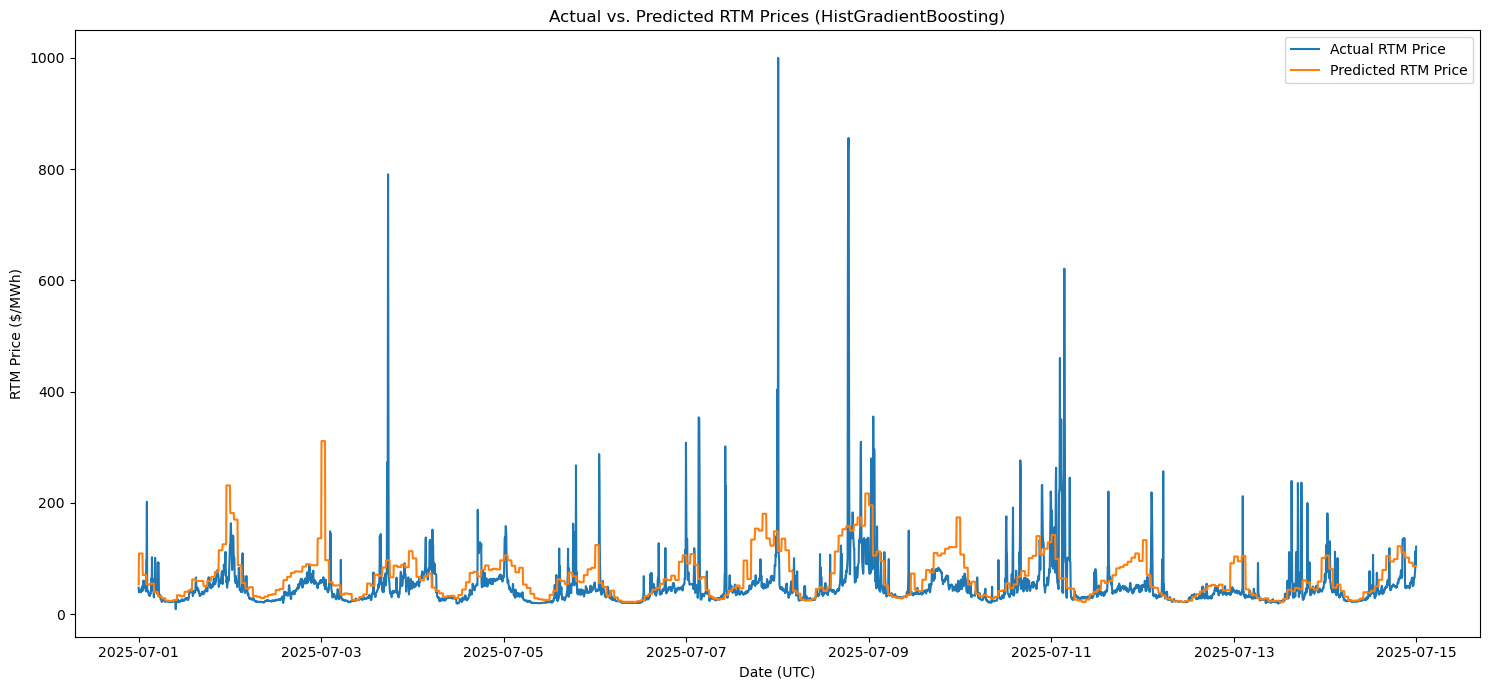

In [29]:
#Plotting the data
validation_results = validation_data[["interval_end_utc", "lmp_rtm"]].copy()
validation_results["predicted"] = val_prediction
plt.figure(figsize=(15, 7))

#show results for only 1 month
month_start = pd.Timestamp("2025-07-01", tz="UTC")
month_end = pd.Timestamp("2025-07-15", tz="UTC")
monthly_results = validation_results.loc[
    (validation_results["interval_end_utc"] >= month_start) &
    (validation_results["interval_end_utc"] < month_end)
]


plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["lmp_rtm"],
    label = "Actual RTM Price"
)

plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["predicted"],
    label = "Predicted RTM Price"
)


plt.xlabel("Date (UTC)")
plt.ylabel("RTM Price ($/MWh)")
plt.title("Actual vs. Predicted RTM Prices (HistGradientBoosting)")
plt.legend()
plt.tight_layout()
plt.show()

**Catboost Regressor**

In [40]:
#cap price at 1000
data["lmp_rtm"] = data["lmp_rtm"].clip(upper=1000)

#convert timestamp to datetime
data["interval_end_utc"] = pd.to_datetime(data["interval_end_utc"], utc=True, errors="coerce")

#set cutoff for data split and validation
test_start = pd.Timestamp("2026-01-01", tz="UTC")
validation_start = pd.Timestamp("2025-07-01", tz="UTC")

#create the training, testing, and validation data
train_data = data.loc[data["interval_end_utc"] < validation_start].copy()
test_data = data.loc[data["interval_end_utc"] >= test_start].copy()
validation_data = data.loc[
    (data["interval_end_utc"] >= validation_start) &
    (data["interval_end_utc"] < test_start)
].copy()

#show number of rows each category holds
print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))
print("Testing rows:", len(test_data))

#Split features
features = ["energy_dam", "congestion_dam", "loss_dam", "miso_wind", "miso_solar", "miso_derated_outages_mw", "miso_forced_outages_mw", "miso_planned_outages_mw", "miso_unplanned_outages_mw"]

X_train = train_data[features]
y_train = train_data["lmp_rtm"]

X_val = validation_data[features]
y_val = validation_data["lmp_rtm"]

#Hist Gradient Boosting Regressor
model = CatBoostRegressor(iterations=1000, learning_rate=0.05, depth=8, l2_leaf_reg=5, random_seed=1)
model.fit(X_train, y_train)
val_prediction = model.predict(X_val)

#evaluate
cat_mae = mean_absolute_error(y_val, val_prediction)
cat_rmse = math.sqrt(mean_squared_error(y_val, val_prediction))
cat_r2 = r2_score(y_val, val_prediction)
print("RMSE: ", cat_rmse)
print("MAE: ", cat_mae)
print("R2: ", cat_r2)

Training rows: 230966
Validation rows: 51831
Testing rows: 71923
0:	learn: 44.7632747	total: 14.4ms	remaining: 14.4s
1:	learn: 44.4382936	total: 26.9ms	remaining: 13.4s
2:	learn: 44.1429980	total: 39.9ms	remaining: 13.3s
3:	learn: 43.8537585	total: 60.2ms	remaining: 15s
4:	learn: 43.5939118	total: 73.2ms	remaining: 14.6s
5:	learn: 43.3617197	total: 85.5ms	remaining: 14.2s
6:	learn: 43.1415007	total: 97.6ms	remaining: 13.9s
7:	learn: 42.9350724	total: 111ms	remaining: 13.7s
8:	learn: 42.7471287	total: 123ms	remaining: 13.5s
9:	learn: 42.5792469	total: 137ms	remaining: 13.6s
10:	learn: 42.4091406	total: 152ms	remaining: 13.7s
11:	learn: 42.2528217	total: 167ms	remaining: 13.8s
12:	learn: 42.0885865	total: 181ms	remaining: 13.7s
13:	learn: 41.9403693	total: 196ms	remaining: 13.8s
14:	learn: 41.8086850	total: 208ms	remaining: 13.6s
15:	learn: 41.6692435	total: 219ms	remaining: 13.4s
16:	learn: 41.5632923	total: 232ms	remaining: 13.4s
17:	learn: 41.4459745	total: 243ms	remaining: 13.3s
18:	

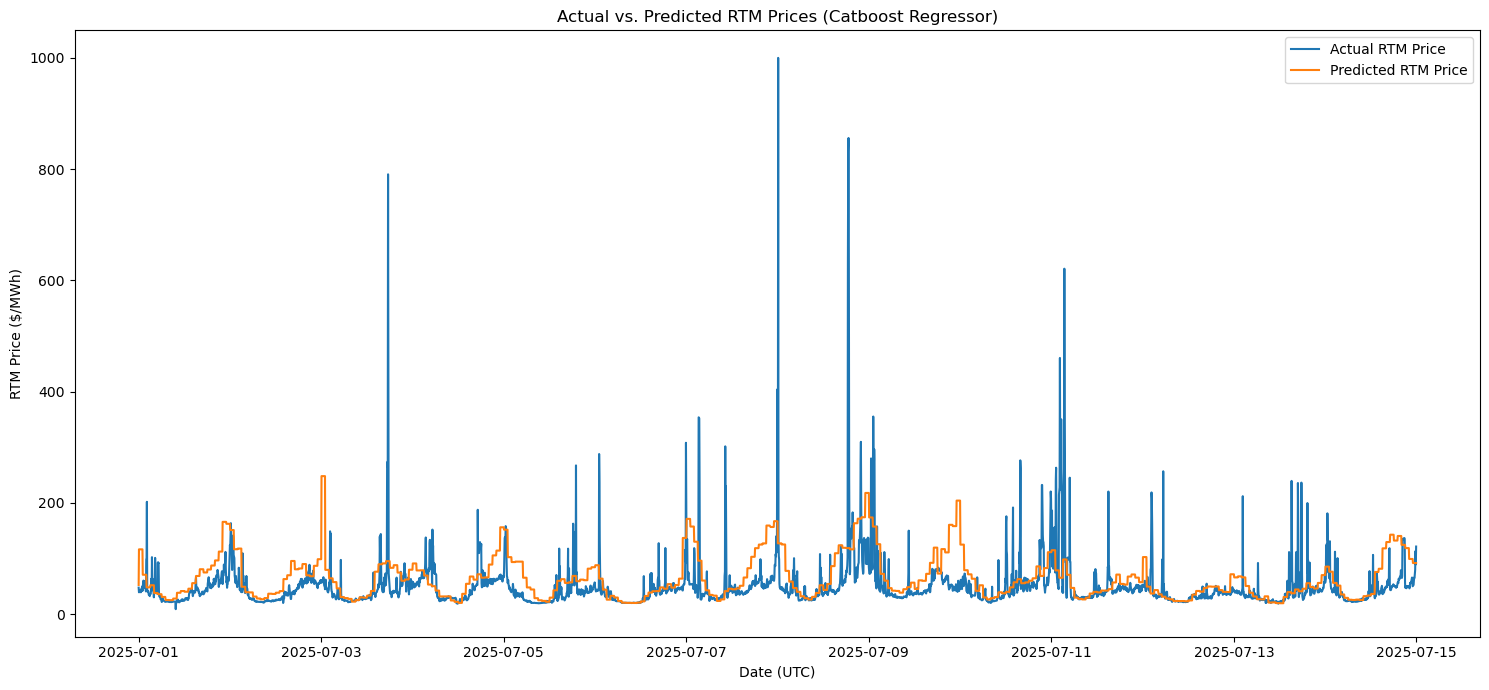

In [31]:
#Plotting the data
validation_results = validation_data[["interval_end_utc", "lmp_rtm"]].copy()
validation_results["predicted"] = val_prediction
plt.figure(figsize=(15, 7))

#show results for only 1 month
month_start = pd.Timestamp("2025-07-01", tz="UTC")
month_end = pd.Timestamp("2025-07-15", tz="UTC")
monthly_results = validation_results.loc[
    (validation_results["interval_end_utc"] >= month_start) &
    (validation_results["interval_end_utc"] < month_end)
]


plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["lmp_rtm"],
    label = "Actual RTM Price"
)

plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["predicted"],
    label = "Predicted RTM Price"
)


plt.xlabel("Date (UTC)")
plt.ylabel("RTM Price ($/MWh)")
plt.title("Actual vs. Predicted RTM Prices (Catboost Regressor)")
plt.legend()
plt.tight_layout()
plt.show()

**LGBM Regressor**

In [41]:
#cap price at 1000
data["lmp_rtm"] = data["lmp_rtm"].clip(upper=1000)

#convert timestamp to datetime
data["interval_end_utc"] = pd.to_datetime(data["interval_end_utc"], utc=True, errors="coerce")

#set cutoff for data split and validation
test_start = pd.Timestamp("2026-01-01", tz="UTC")
validation_start = pd.Timestamp("2025-07-01", tz="UTC")

#create the training, testing, and validation data
train_data = data.loc[data["interval_end_utc"] < validation_start].copy()
test_data = data.loc[data["interval_end_utc"] >= test_start].copy()
validation_data = data.loc[
    (data["interval_end_utc"] >= validation_start) &
    (data["interval_end_utc"] < test_start)
].copy()

#show number of rows each category holds
print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))
print("Testing rows:", len(test_data))

#Split features
features = ["energy_dam", "congestion_dam", "loss_dam", "miso_wind", "miso_solar", "miso_derated_outages_mw", "miso_forced_outages_mw", "miso_planned_outages_mw", "miso_unplanned_outages_mw"]

X_train = train_data[features]
y_train = train_data["lmp_rtm"]

X_val = validation_data[features]
y_val = validation_data["lmp_rtm"]

#LGBM Regressor
model = LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=31, max_depth=1, min_child_samples=30, random_state=1)
model.fit(X_train, y_train)
val_prediction = model.predict(X_val)

#evaluate
lgbm_mae = mean_absolute_error(y_val, val_prediction)
lgbm_rmse = math.sqrt(mean_squared_error(y_val, val_prediction))
lgbm_r2 = r2_score(y_val, val_prediction)
print("RMSE: ", lgbm_rmse)
print("MAE: ", lgbm_mae)
print("R2: ", lgbm_r2)

Training rows: 230966
Validation rows: 51831
Testing rows: 71923
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005544 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2294
[LightGBM] [Info] Number of data points in the train set: 230966, number of used features: 9
[LightGBM] [Info] Start training from score 29.909093
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

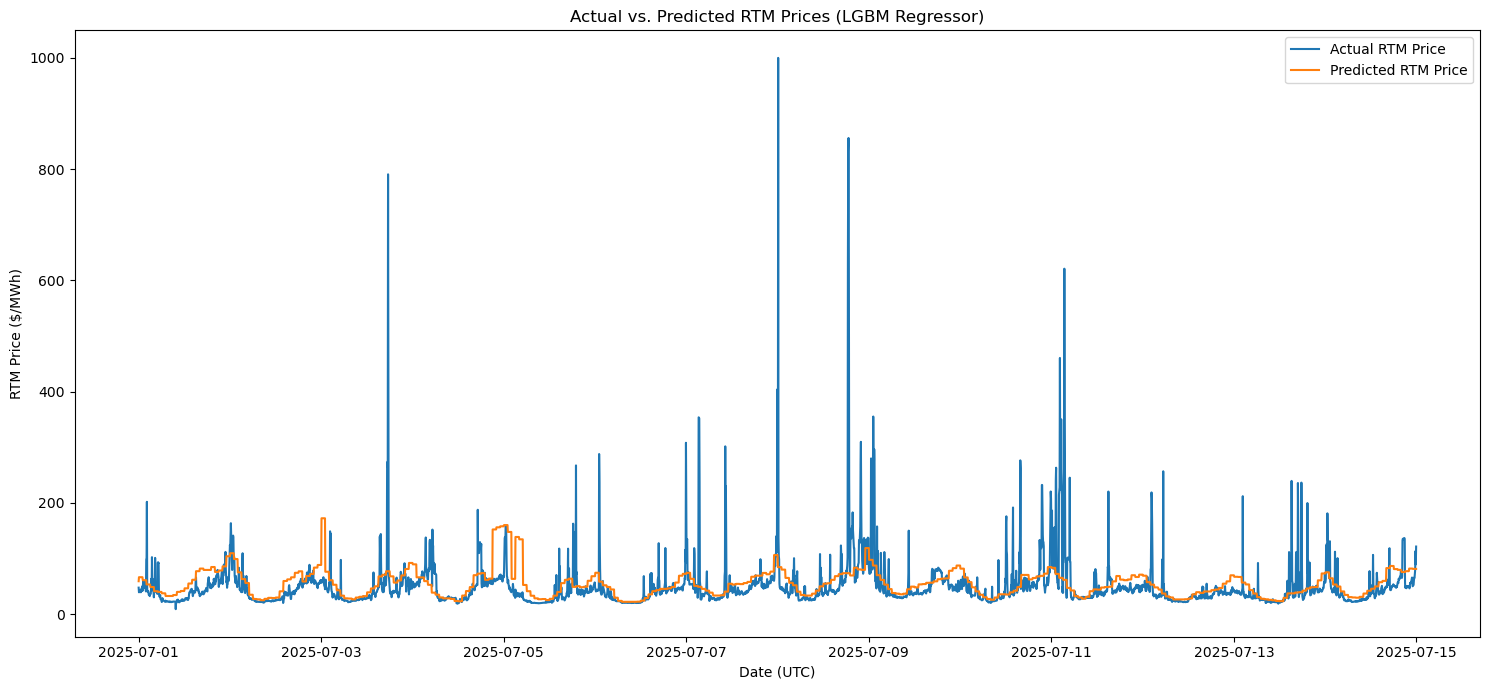

In [33]:
#Plotting the data
validation_results = validation_data[["interval_end_utc", "lmp_rtm"]].copy()
validation_results["predicted"] = val_prediction
plt.figure(figsize=(15, 7))

#show results for only 1 month
month_start = pd.Timestamp("2025-07-01", tz="UTC")
month_end = pd.Timestamp("2025-07-15", tz="UTC")
monthly_results = validation_results.loc[
    (validation_results["interval_end_utc"] >= month_start) &
    (validation_results["interval_end_utc"] < month_end)
]


plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["lmp_rtm"],
    label = "Actual RTM Price"
)

plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["predicted"],
    label = "Predicted RTM Price"
)


plt.xlabel("Date (UTC)")
plt.ylabel("RTM Price ($/MWh)")
plt.title("Actual vs. Predicted RTM Prices (LGBM Regressor)")
plt.legend()
plt.tight_layout()
plt.show()

**Extra Trees Regressor**

In [42]:
#cap price at 1000
data["lmp_rtm"] = data["lmp_rtm"].clip(upper=1000)

#convert timestamp to datetime
data["interval_end_utc"] = pd.to_datetime(data["interval_end_utc"], utc=True, errors="coerce")

#set cutoff for data split and validation
test_start = pd.Timestamp("2026-01-01", tz="UTC")
validation_start = pd.Timestamp("2025-07-01", tz="UTC")

#create the training, testing, and validation data
train_data = data.loc[data["interval_end_utc"] < validation_start].copy()
test_data = data.loc[data["interval_end_utc"] >= test_start].copy()
validation_data = data.loc[
    (data["interval_end_utc"] >= validation_start) &
    (data["interval_end_utc"] < test_start)
].copy()

#show number of rows each category holds
print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))
print("Testing rows:", len(test_data))

#Split features
features = ["energy_dam", "congestion_dam", "loss_dam", "miso_wind", "miso_solar", "miso_derated_outages_mw", "miso_forced_outages_mw", "miso_planned_outages_mw", "miso_unplanned_outages_mw"]

X_train = train_data[features]
y_train = train_data["lmp_rtm"]

X_val = validation_data[features]
y_val = validation_data["lmp_rtm"]

#Extra Trees Regressor
model = ExtraTreesRegressor(n_estimators=300, max_features=1, min_samples_split=2, min_samples_leaf=2, random_state=1)
model.fit(X_train, y_train)
val_prediction = model.predict(X_val)

#evaluate
et_mae = mean_absolute_error(y_val, val_prediction)
et_rmse = math.sqrt(mean_squared_error(y_val, val_prediction))
et_r2 = r2_score(y_val, val_prediction)
print("RMSE: ", et_rmse)
print("MAE: ", et_mae)
print("R2: ", et_r2)

Training rows: 230966
Validation rows: 51831
Testing rows: 71923
RMSE:  48.82649625304215
MAE:  17.56433500901306
R2:  0.160919255734691


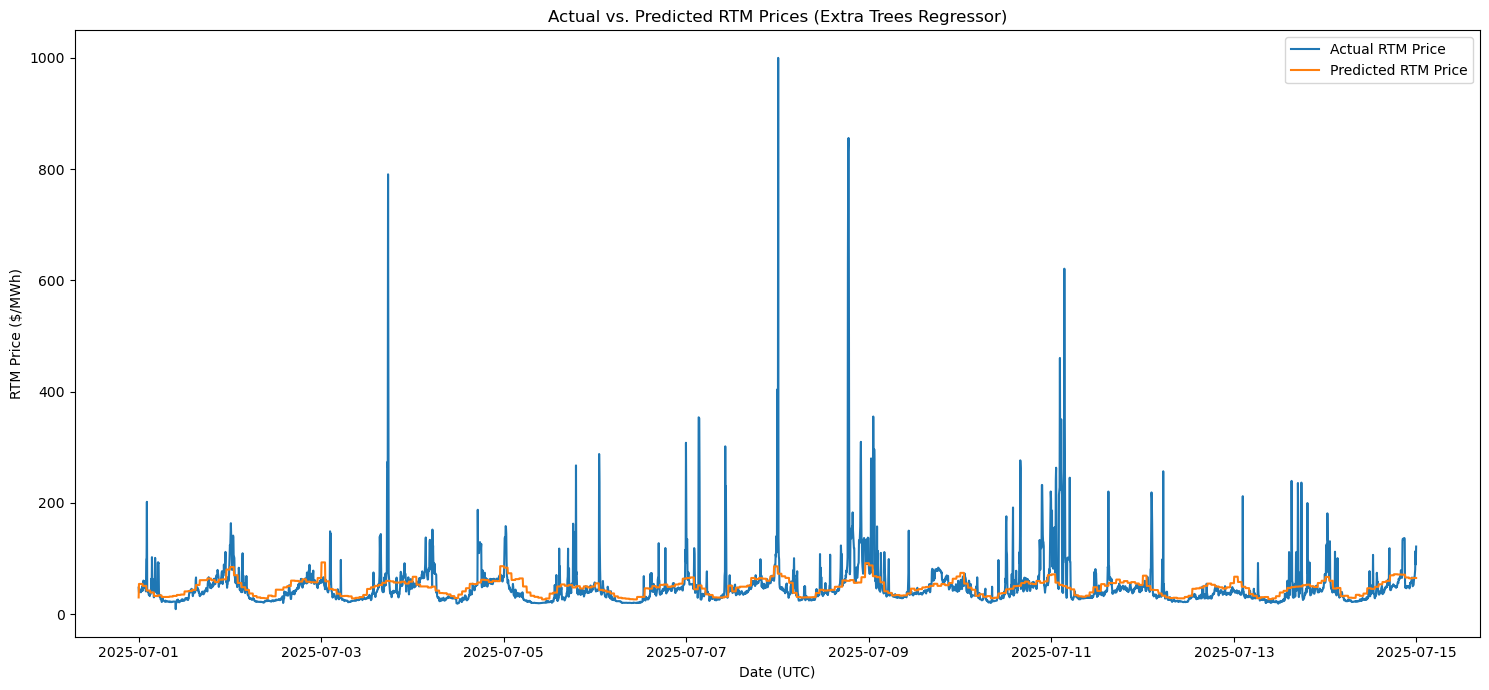

In [35]:
#Plotting the data
validation_results = validation_data[["interval_end_utc", "lmp_rtm"]].copy()
validation_results["predicted"] = val_prediction
plt.figure(figsize=(15, 7))

#show results for only 1 month
month_start = pd.Timestamp("2025-07-01", tz="UTC")
month_end = pd.Timestamp("2025-07-15", tz="UTC")
monthly_results = validation_results.loc[
    (validation_results["interval_end_utc"] >= month_start) &
    (validation_results["interval_end_utc"] < month_end)
]


plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["lmp_rtm"],
    label = "Actual RTM Price"
)

plt.plot(
    monthly_results["interval_end_utc"],
    monthly_results["predicted"],
    label = "Predicted RTM Price"
)


plt.xlabel("Date (UTC)")
plt.ylabel("RTM Price ($/MWh)")
plt.title("Actual vs. Predicted RTM Prices (Extra Trees Regressor)")
plt.legend()
plt.tight_layout()
plt.show()

**Organizing and Evaluating the Results**

In [ ]:
#organize the results and find the best by sorting by RMSE

evaluation_results = {
    "Random Forest": {
        "RMSE": rf_rmse,
        "MAE": rf_mae,
        "R2": rf_r2
    },
    "LightGBM": {
        "RMSE": lgbm_rmse,
        "MAE": lgbm_mae,
        "R2": lgbm_r2
    },
    "XGBoost": {
        "RMSE": xgb_rmse,
        "MAE": xgb_mae,
        "R2": xgb_r2
    },
    "CatBoost": {
        "RMSE": cat_rmse,
        "MAE": cat_mae,
        "R2": cat_r2
    },
    "HistGradientBoosting": {
        "RMSE": hist_rmse,
        "MAE": hist_mae,
        "R2": hist_r2
    },
    "Extra Trees": {
        "RMSE": et_rmse,
        "MAE": et_mae,
        "R2": et_r2
    }
}

evaluation_results = pd.DataFrame.from_dict(evaluation_results, orient="index")
evaluation_results = evaluation_results.sort_values("RMSE", ascending=True)
evaluation_results


,RMSE,MAE,R2
Extra Trees,48.826496,17.564335,0.160919
LightGBM,48.944731,19.210290,0.156851
CatBoost,51.187692,21.644011,0.077803
XGBoost,52.523334,22.181764,0.029049
Random Forest,53.176385,23.828356,0.004754
HistGradientBoosting,53.705752,22.753885,-0.015159
